# Marketing Mix Model: where should the next £ go?

**Question:** where should the brand spend more or less to win *new customers* efficiently, if one extra new customer may cost at most **£40**?
**Baseline:** September 2026 average daily spend, run for the next 30 days under normal trading (no promotions, no Black Friday / Cyber Monday).

**The short version**
- At today's spend, every channel buys extra customers for less than £40: Bing £15, Meta £29, Google £32, Pinterest £33.
- Meta is the biggest lever, and the model sees almost no diminishing returns there. That is also the least certain part, so test it first: +20% for 30 days is about +£15k for roughly +530 customers (about £29 each).
- Google gets too expensive first (around 1.5x today's spend). Pinterest is the weakest and the least certain.
- Cutting is not attractive: -10% loses about 616 customers (£28 saved per customer lost). Moving money between channels barely helps (about +1%).
- These are model estimates, not guarantees. I did not refit with different assumptions, and only a controlled test can show what ads really cause.

In [4]:
import warnings, os, sys
warnings.filterwarnings("ignore")

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass

import arviz as az
import pymc as pm
import pymc_marketing
from pymc_marketing.mmm import MMM, GeometricAdstock, LogisticSaturation

print("python", sys.version.split()[0], "| pymc", pm.__version__, "| pymc-marketing", pymc_marketing.__version__)

# ----------------------------- settings -----------------------------
DATA_FILE = "MMM_Candidate_Brief.xlsx"       # the Excel file from the company
OUT_DIR = "outputs"                          # charts and tables are saved here
SEED = 42                                    # makes random numbers repeatable
CPA_TARGET = 40.0                            # max acceptable cost of one EXTRA new customer (£)
HORIZON = 30                                 # days we look ahead
HOLDOUT_DAYS = 56                            # last 8 weeks are hidden for the out-of-sample test
L_MAX = 8                                    # how many days an ad can keep working (adstock length)
HIST_DAYS = 30                               # real days before the horizon, so earlier ads still "echo"
N_KEEP = 1000                                # posterior draws used for the scenarios
CHAINS, DRAWS, TUNE = 4, 1000, 1000          # sampler size

CHANNELS = ["bing", "google", "meta", "pinterest"]
CONTROLS = ["promo_discount", "black_friday", "cyber_monday", "bfcm_window", "christmas",
            "dow_1", "dow_2", "dow_3", "dow_4", "dow_5", "dow_6"]

os.makedirs(OUT_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

python 3.13.9 | pymc 6.3.2 | pymc-marketing 1.3.0


## 1. Data and quality checks

In [5]:
raw = pd.read_excel(DATA_FILE, sheet_name="Daily Data")
assert raw.shape[1] == 15, f"Expected 15 columns, found {raw.shape[1]}"

raw.columns = [
    "date", "sales_inc_tax", "sales_ex_tax", "purchasing_customers", "orders", "new_customers",
    "bing", "google", "meta", "pinterest", "total_spend",
    "promo_discount", "black_friday", "cyber_monday", "bfcm_window",
]

# dates may arrive as real dates or as Excel serial numbers - handle both
if pd.api.types.is_numeric_dtype(raw["date"]):
    raw["date"] = pd.to_datetime(raw["date"], unit="D", origin="1899-12-30")
else:
    raw["date"] = pd.to_datetime(raw["date"])

df = raw.sort_values("date").reset_index(drop=True)
display(df.head())
print(df.shape, df["date"].min().date(), "->", df["date"].max().date())

,date,sales_inc_tax,sales_ex_tax,purchasing_customers,orders,new_customers,bing,google,meta,pinterest,total_spend,promo_discount,black_friday,cyber_monday,bfcm_window
0,2024-10-01,65244.10,54370.08,706,721,458,334.72,2657.94,2393.94,512.70,5899.30,0.0,0,0,0
1,2024-10-02,69274.63,57728.86,710,724,468,310.00,3087.64,2462.26,468.30,6328.20,0.0,0,0,0
2,2024-10-03,68498.62,57082.18,721,734,476,321.55,3215.14,2965.07,469.93,6971.69,0.0,0,0,0
3,2024-10-04,73992.31,61660.26,765,788,504,391.43,3018.59,3110.63,512.49,7033.14,0.0,0,0,0
4,2024-10-05,71122.07,59268.39,684,708,425,379.63,2492.08,2738.47,550.13,6160.31,0.0,0,0,0


(730, 15) 2024-10-01 -> 2026-09-30


In [6]:
checks = []
def add_check(name, ok, detail=""):
    checks.append({"check": name, "result": "PASS" if ok else "CHECK", "detail": detail})

all_days = pd.date_range(df["date"].min(), df["date"].max(), freq="D")
missing_days = all_days.difference(df["date"])
add_check("No missing dates", len(missing_days) == 0,
          f"{len(df)} rows vs {len(all_days)} calendar days ({len(missing_days)} missing)")
add_check("No duplicate dates", not df["date"].duplicated().any(),
          f"{int(df['date'].duplicated().sum())} duplicates")
add_check("No missing values", df.isna().sum().sum() == 0, f"{int(df.isna().sum().sum())} empty cells")

numeric = df.drop(columns="date")
add_check("No negative numbers", (numeric < 0).sum().sum() == 0, f"{int((numeric < 0).sum().sum())} negatives")

gap = (df[CHANNELS].sum(axis=1) - df["total_spend"]).abs().max()
add_check("Channel spends add up to total spend", gap <= 0.05, f"largest gap £{gap:.2f}")

ratio = df["sales_inc_tax"] / df["sales_ex_tax"]
add_check("Sales incl. tax = 1.20 x excl. tax (20% VAT)", ratio.between(1.19, 1.21).all(),
          f"ratio between {ratio.min():.3f} and {ratio.max():.3f}")

order_ok = (df["new_customers"] <= df["purchasing_customers"]) & (df["purchasing_customers"] <= df["orders"])
add_check("new customers <= purchasing customers <= orders", order_ok.all(), f"{int((~order_ok).sum())} violations")

flags_ok = all(df[c].isin([0, 1]).all() for c in ["black_friday", "cyber_monday", "bfcm_window"])
add_check("Event flags contain only 0/1", flags_ok)
add_check("Promo discount is a fraction between 0 and 1 (0.25 = 25%)", df["promo_discount"].between(0, 1).all(),
          f"max {df['promo_discount'].max():.2f}")
add_check("BF and CM days lie inside the BF/CM window", ((df["black_friday"] + df["cyber_monday"]) <= df["bfcm_window"]).all())

display(pd.DataFrame(checks))

,check,result,detail
0,No missing dates,PASS,730 rows vs 730 calendar days (0 missing)
1,No duplicate dates,PASS,0 duplicates
2,No missing values,PASS,0 empty cells
3,No negative numbers,PASS,0 negatives
4,Channel spends add up to total spend,PASS,largest gap £0.00
5,Sales incl. tax = 1.20 x excl. tax (20% VAT),PASS,ratio between 1.200 and 1.200
6,new customers <= purchasing customers <= orders,PASS,0 violations
7,Event flags contain only 0/1,PASS,
8,Promo discount is a fraction between 0 and 1 (...,PASS,max 0.25
9,BF and CM days lie inside the BF/CM window,PASS,


In [7]:
# Units: not just stated, but checked against what a daily £ amount or a count should look like
unit_checks = []

for ch in CHANNELS + ["total_spend"]:
    lo, hi = df[ch].min(), df[ch].max()
    unit_checks.append({"column": ch, "min": round(lo, 2), "max": round(hi, 2),
                        "plausible?": "YES (£ per day)" if (lo >= 0 and hi < 100_000) else "CHECK"})

rev_per_spend = df["sales_ex_tax"].mean() / df["total_spend"].mean()
unit_checks.append({"column": "sales_ex_tax vs total_spend", "min": "-", "max": "-",
                    "plausible?": f"revenue / ad spend = {rev_per_spend:.1f}x ({'plausible' if 2 < rev_per_spend < 200 else 'CHECK'})"})

for col in ["purchasing_customers", "orders", "new_customers"]:
    frac = (df[col] % 1).max()
    unit_checks.append({"column": col, "min": int(df[col].min()), "max": int(df[col].max()),
                        "plausible?": "YES (whole numbers)" if frac < 0.01 else "CHECK (has decimals)"})

promo_max = df["promo_discount"].max()
unit_checks.append({"column": "promo_discount", "min": df["promo_discount"].min(), "max": promo_max,
                    "plausible?": "YES (fraction, 0.25 = 25%)" if promo_max <= 1 else "CHECK (looks like % not fraction)"})
display(pd.DataFrame(unit_checks))

aov = (df["sales_ex_tax"] / df["orders"]).mean()
print(f"Total spend over 2 years: £{df['total_spend'].sum():,.0f}")
print(f"Average order value (sales ex tax / orders): £{aov:.2f} - {'plausible for e-commerce' if 20 < aov < 500 else 'CHECK'}")
print(f"New customers per day: min {df.new_customers.min():.0f}, median {df.new_customers.median():.0f}, max {df.new_customers.max():.0f}")

,column,min,max,plausible?
0,bing,98.0,1069.95,YES (£ per day)
1,google,848.27,13487.88,YES (£ per day)
2,meta,518.24,19251.13,YES (£ per day)
3,pinterest,56.59,3029.0,YES (£ per day)
4,total_spend,1993.5,36653.03,YES (£ per day)
5,sales_ex_tax vs total_spend,-,-,revenue / ad spend = 9.0x (plausible)
6,purchasing_customers,231,3020,YES (whole numbers)
7,orders,236,3088,YES (whole numbers)
8,new_customers,127,2290,YES (whole numbers)
9,promo_discount,0.0,0.25,"YES (fraction, 0.25 = 25%)"


Total spend over 2 years: £4,383,041
Average order value (sales ex tax / orders): £78.64 - plausible for e-commerce
New customers per day: min 127, median 385, max 2290


In [8]:
# Unusual days: how far is each day from its own surroundings?
# Rolling median + MAD (median absolute deviation). The threshold comes from the data's own spread,
# so it adapts to quiet and busy seasons instead of using a fixed cut-off.
WINDOW = 21          # 3 weeks: wide enough not to swallow a short peak
THRESHOLD = 3.5      # in MAD units (common range 2.5-3.5)
BUDGET_COL = "total_spend"

rolling_med = df["new_customers"].rolling(WINDOW, center=True, min_periods=7).median()
abs_dev = (df["new_customers"] - rolling_med).abs()
rolling_mad = abs_dev.rolling(WINDOW, center=True, min_periods=7).median()
# 0.6745 makes MAD comparable to a standard deviation; 1e-9 avoids dividing by zero
modified_z = 0.6745 * (df["new_customers"] - rolling_med) / (rolling_mad + 1e-9)

odd = df.loc[modified_z.abs() > THRESHOLD,
             ["date", "new_customers", BUDGET_COL, "promo_discount", "bfcm_window", "black_friday", "cyber_monday"]].copy()
odd["rolling_median"] = rolling_med[odd.index].round(0)
odd["modified_z_score"] = modified_z[odd.index].round(2)
odd["direction"] = (odd["new_customers"] > odd["rolling_median"]).map({True: "up", False: "down"})

# did ad spend move too? compare it with its own normal level
rolling_spend_med = df[BUDGET_COL].rolling(WINDOW, center=True, min_periods=7).median()
odd["rolling_median_spend"] = rolling_spend_med[odd.index].round(2)
odd["spend_direction"] = (odd[BUDGET_COL] > odd["rolling_median_spend"]).map({True: "up", False: "down/same"})

display(odd.sort_values("modified_z_score").reset_index(drop=True))
print(f"\nThreshold |z| > {THRESHOLD} (window {WINDOW} days). Found {len(odd)} unusual days out of {len(df)}.")

,date,new_customers,total_spend,promo_discount,bfcm_window,black_friday,cyber_monday,rolling_median,modified_z_score,direction,rolling_median_spend,spend_direction
0,2025-12-24,177,3942.05,0.00,0,0,0,645.0,-4.57,down,8023.81,down/same
1,2024-12-24,130,2173.33,0.00,0,0,0,449.0,-4.30,down,3654.18,down/same
2,2024-12-25,127,1993.50,0.00,0,0,0,443.0,-4.18,down,3543.30,down/same
3,2025-08-30,258,3783.37,0.00,0,0,0,326.0,-4.17,down,3771.15,up
4,2025-12-25,190,3801.80,0.00,0,0,0,608.0,-4.09,down,7897.13,down/same
5,2025-06-29,403,4982.87,0.00,0,0,0,333.0,3.63,up,4625.44,up
6,2025-10-26,595,6851.86,0.00,0,0,0,498.0,3.63,up,6982.70,down/same
7,2026-03-15,452,6284.26,0.00,0,0,0,386.0,3.71,up,5982.14,up
8,2025-09-07,390,3492.68,0.00,0,0,0,329.0,3.74,up,3806.91,down/same
9,2026-06-21,664,8402.59,0.10,0,0,0,411.0,4.16,up,7224.18,up



Threshold |z| > 3.5 (window 21 days). Found 23 unusual days out of 730.


All 10 checks passed: 730 days in a row, no gaps, duplicates, empty or negative cells; channel spends add up to the total; sales incl. tax are exactly 1.20x sales excl. tax (20% VAT); customers never exceed orders. Units look right as well: spend in £ per day (£4.4M over two years), average order £78.64, discount stored as a fraction. These are sanity checks, not proof, but nothing suspicious is noticeable.

Unusual days (23 flagged). Almost all have a clear story:
- Black Friday / Cyber Monday weeks: customers, discounts (10-25%) and ad spend all jump together.
- Christmas Eve and Day, both years: new customers about 70% below normal, ad spend 40-50% below normal.
- 10% discount weeks in June: customers 31-62% above normal, while spend is at most 18% above normal.
- Four ordinary Sundays (17-21% above the rolling median, spend within +/-8% of normal): Sunday is simply the strongest weekday. The model has day-of-week controls for this.
- 30 Aug 2025 (a Saturday): customers 21% below normal at normal spend. The data do not say why, so I treat it as noise (one day out of 730).

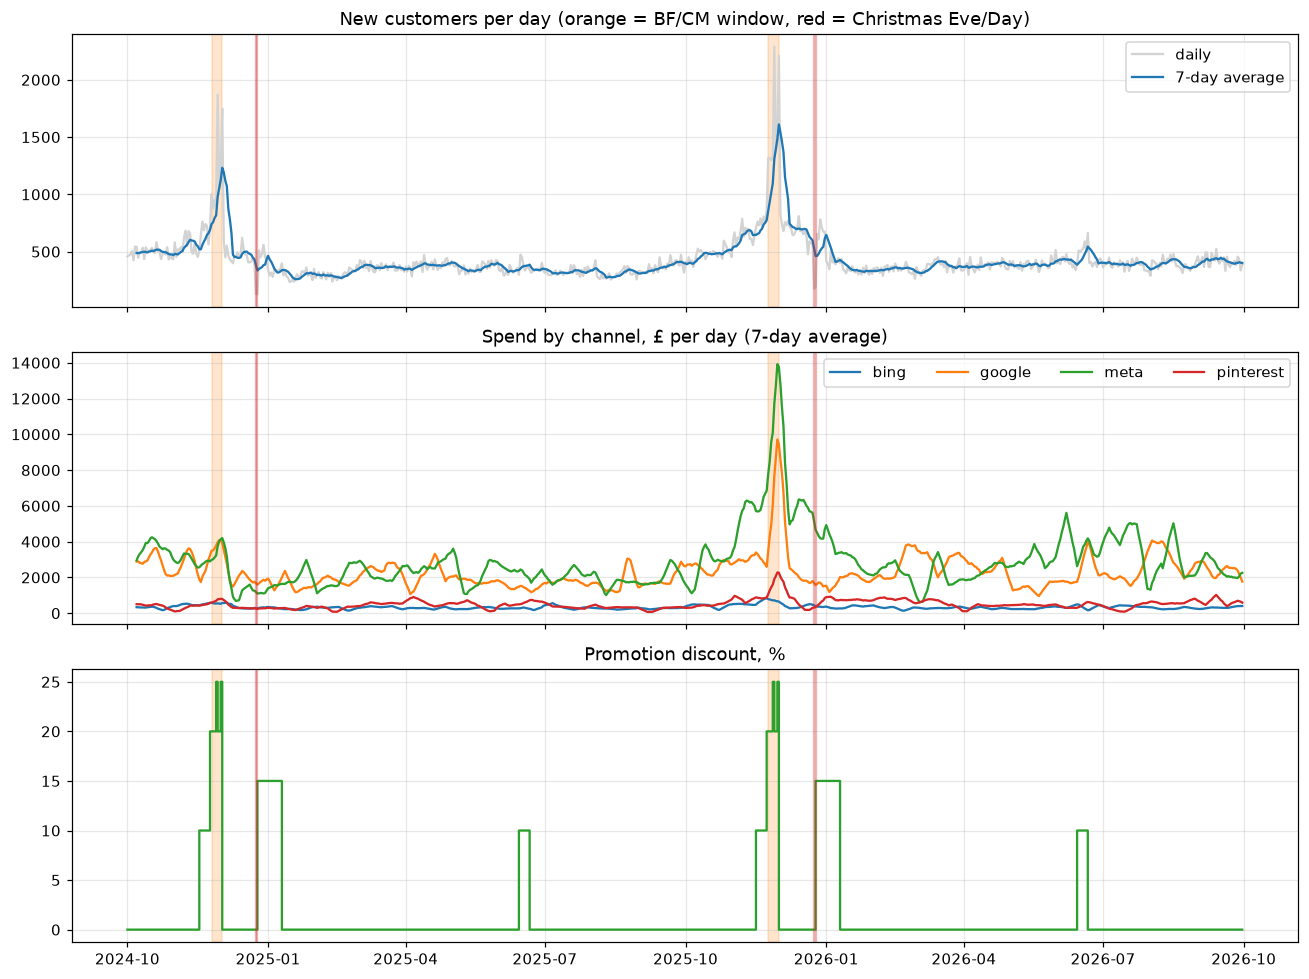

In [9]:
# features the model needs
df["christmas"] = ((df["date"].dt.month == 12) & (df["date"].dt.day.isin([24, 25]))).astype(int)
dow = df["date"].dt.dayofweek                      # Monday = 0 ... Sunday = 6
for d in range(1, 7):
    df[f"dow_{d}"] = (dow == d).astype(int)        # Monday is the reference day

def shade_events(ax):
    win = df["bfcm_window"].to_numpy()
    starts = df.index[(win == 1) & (np.r_[0, win[:-1]] == 0)]
    ends = df.index[(win == 1) & (np.r_[win[1:], 0] == 0)]
    for s, e in zip(starts, ends):
        ax.axvspan(df["date"][s], df["date"][e], color="tab:orange", alpha=0.2)
    for d in df.loc[df["christmas"] == 1, "date"]:
        ax.axvline(d, color="tab:red", alpha=0.35)

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
axes[0].plot(df["date"], df["new_customers"], color="lightgrey", label="daily")
axes[0].plot(df["date"], df["new_customers"].rolling(7).mean(), color="tab:blue", label="7-day average")
axes[0].set_title("New customers per day (orange = BF/CM window, red = Christmas Eve/Day)")
axes[0].legend(); shade_events(axes[0])

for ch in CHANNELS:
    axes[1].plot(df["date"], df[ch].rolling(7).mean(), label=ch)
axes[1].set_title("Spend by channel, £ per day (7-day average)")
axes[1].legend(ncol=4); shade_events(axes[1])

axes[2].step(df["date"], df["promo_discount"] * 100, color="tab:green")
axes[2].set_title("Promotion discount, %"); shade_events(axes[2])
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/01_overview.png"); plt.show()

In [10]:
# Black Friday 2024 vs 2025: same discount schedule, very different spend
rows = []
for y in (2024, 2025):
    sale = df[(df["date"] >= f"{y}-11-01") & (df["date"] <= f"{y}-12-05") & (df["promo_discount"] > 0)]
    start = sale["date"].min()
    pre = df[(df["date"] >= start - pd.Timedelta(days=45)) & (df["date"] <= start - pd.Timedelta(days=15))]
    rows.append({"year": y, "sale from": start.date(), "to": sale["date"].max().date(), "days": len(sale),
                 "avg discount": sale["promo_discount"].mean(),
                 "sale spend £": sale["total_spend"].sum(), "sale new customers": sale["new_customers"].sum(),
                 "pre-sale customers/day": pre["new_customers"].mean(), "pre-sale spend £/day": pre["total_spend"].mean()})
bf = pd.DataFrame(rows).set_index("year")
display(bf.round(2))

extra_spend_bf = bf.loc[2025, "sale spend £"] - bf.loc[2024, "sale spend £"]
extra_cust_bf = bf.loc[2025, "sale new customers"] - bf.loc[2024, "sale new customers"]
print(f"2025 vs 2024: spend x{bf.loc[2025, 'sale spend £'] / bf.loc[2024, 'sale spend £']:.2f}, "
      f"new customers {extra_cust_bf / bf.loc[2024, 'sale new customers']:+.0%}")
print(f"The extra £{extra_spend_bf:,.0f} of spend came with {extra_cust_bf:,.0f} extra new customers -> about £{extra_spend_bf / extra_cust_bf:,.0f} each")
print("Crude: two different years, other things changed too. A sanity check, not an estimate.")

,sale from,to,days,avg discount,sale spend £,sale new customers,pre-sale customers/day,pre-sale spend £/day
year,,,,,,,,
2024,2024-11-18,2024-12-02,15,0.16,126328.21,14451,494.65,6908.09
2025,2025-11-17,2025-12-01,15,0.16,284806.52,18010,489.35,6677.57


2025 vs 2024: spend x2.25, new customers +25%
The extra £158,478 of spend came with 3,559 extra new customers -> about £45 each
Crude: two different years, other things changed too. A sanity check, not an estimate.


- New customers peak every year in Black Friday / Cyber Monday week, drop sharply on Christmas Eve and Day, then bounce back with the 15% post-Christmas sale.
- Meta is the biggest budget (48% of two-year spend), then Google (38%), Pinterest (8%) and Bing (about 5-6%). Meta and Google both ramp up hard in sale periods, most of all in 2025.
- Outside sales, new customers sit at a fairly steady 320-400 a day (higher in autumn).
- Same discounts, very different spend. The 2024 and 2025 sales had the same discount schedule, yet 2025 spend was 2.25x higher while new customers rose only 25%, and the normal level before the sale was the same in both years. More money bought less than proportional growth. This is a rough comparison of two years, not a model result.

## 2. Baseline plan (September 2026 average daily spend)

In [11]:
sept = df[(df["date"] >= "2026-09-01") & (df["date"] <= "2026-09-30")]
assert len(sept) == 30

if sept["promo_discount"].max() > 0 or sept["bfcm_window"].max() > 0:
    print("WARNING: September 2026 contains promotions or BF/CM days - decide what 'normal trading' means and note it.")
else:
    print("OK: September 2026 had no promotions and no BF/CM days, so it is a clean 'normal trading' reference.")

base_daily = sept[CHANNELS].mean()                       # £ per day, per channel
base_new_30d = sept["new_customers"].mean() * HORIZON    # reference level of new customers over 30 days
hist = df[CHANNELS].tail(HIST_DAYS).to_numpy()           # real spend of the last days (carry-over into the horizon)

summary = pd.DataFrame({
    "avg daily spend £": base_daily.round(2),
    "share of total": (base_daily / base_daily.sum()).round(3),
    "30-day spend £": (base_daily * HORIZON).round(0),
})
display(summary)
print(f"Total: £{base_daily.sum():,.0f} per day, £{base_daily.sum() * HORIZON:,.0f} over {HORIZON} days")
print(f"September 2026 new customers per day: {sept['new_customers'].mean():.1f}  -> reference for {HORIZON} days: {base_new_30d:,.0f}")
print(f"Average cost per new customer in September (ALL spend / ALL new customers): "
      f"£{sept['total_spend'].sum() / sept['new_customers'].sum():.2f}")
print("This is an AVERAGE. The £40 limit applies to the cost of EXTRA customers (the margin), which is higher.")

OK: September 2026 had no promotions and no BF/CM days, so it is a clean 'normal trading' reference.


,avg daily spend £,share of total,30-day spend £
bing,331.44,0.058,9943.0
google,2264.95,0.395,67949.0
meta,2509.40,0.437,75282.0
pinterest,634.51,0.111,19035.0


Total: £5,740 per day, £172,209 over 30 days
September 2026 new customers per day: 418.6  -> reference for 30 days: 12,558
Average cost per new customer in September (ALL spend / ALL new customers): £13.71
This is an AVERAGE. The £40 limit applies to the cost of EXTRA customers (the margin), which is higher.


Baseline is £5,740 a day (£172k over 30 days) for about 419 new customers a day, so 12,558 over 30 days. The average new customer costs £13.71, but that is an average. The £40 limit is about the next customer, and the next one always costs more.

## 3. The model
New customers per day = baseline level + yearly season + controls (discount, BF/CM flags, Christmas, weekday) + the four channels. Each channel's spend gets two twists: adstock (an ad keeps working for a few days, fading a bit each day) and saturation (each extra £ adds less than the last one). It is Bayesian, so every number comes with a range.

After fitting, I check the model's global parameters: adstock (ad memory), saturation (diminishing returns), sigma (noise), intercept (baseline) and gamma (controls such as Black Friday and discount). If the sampler did not settle on those, nothing built on top can be trusted.

In [12]:
MODEL_COLS = ["date"] + CHANNELS + CONTROLS

@dataclass
class Fit:
    mmm: object
    data: pd.DataFrame
    l_max: int
    tgt_scale: float
    ch_scale: np.ndarray

def fit_model(data, l_max=L_MAX, yearly_seasonality=2, draws=DRAWS, tune=TUNE, chains=CHAINS):
    data = data.reset_index(drop=True)
    X = data[MODEL_COLS]
    y = data["new_customers"].rename("y")          # the library expects the target to be called "y"
    mmm = MMM(
        date_column="date",
        channel_columns=CHANNELS,
        control_columns=CONTROLS,
        adstock=GeometricAdstock(l_max=l_max),
        saturation=LogisticSaturation(),
        yearly_seasonality=yearly_seasonality,     # smooth yearly wave (2 Fourier terms)
    )
    mmm.fit(X=X, y=y, chains=chains, draws=draws, tune=tune, target_accept=0.9, random_seed=SEED)
    # PyMC-Marketing divides spend and target by their maximum (max-abs scaling); we keep those numbers
    return Fit(mmm=mmm, data=data, l_max=l_max, tgt_scale=float(y.max()), ch_scale=X[CHANNELS].max().to_numpy())

def diagnostics(fit):
    idata = fit.mmm.idata
    keep = [v for v in idata.posterior.data_vars
            if any(k in v for k in ("adstock", "saturation", "sigma", "intercept", "gamma"))]
    summ = az.summary(idata, var_names=keep)
    div = int(idata.sample_stats["diverging"].sum())
    print(f"max r_hat  = {summ['r_hat'].max():.3f}   (want < 1.01)")
    print(f"min ESS    = {summ['ess_bulk'].min():.0f}    (want > 400)")
    print(f"divergences= {div}      (want 0 or very few)")
    return summ

def to_draws(pred, n_last, y_mean, tgt_scale):
    """Turn PyMC-Marketing's prediction object into a plain array: (draws, days)."""
    if hasattr(pred, "data_vars"):
        names = list(pred.data_vars)
        da = pred["y"] if "y" in names else pred[names[0]]
    else:
        da = pred
    dims = list(da.dims)
    time_dim = "date" if "date" in dims else [d for d in dims if d not in ("chain", "draw", "sample")][-1]
    other = [d for d in dims if d != time_dim]
    arr = np.asarray(da.transpose(*other, time_dim).values)
    arr = arr.reshape(-1, arr.shape[-1])[:, -n_last:]
    if arr.mean() < 0.05 * y_mean:          # values look scaled to 0-1: bring them back to customers
        print("NOTE: predictions looked scaled, multiplying by the target scale.")
        arr = arr * tgt_scale
    return arr

def forecast(fit, future_df, prepend=True):
    """Predict new customers for future_df. For days AFTER the training period, the last days of
    training data are put in front, so that the adstock 'echo' of earlier spend is not lost."""
    if prepend:
        ext = pd.concat([fit.data.tail(HIST_DAYS), future_df], ignore_index=True)[MODEL_COLS]
    else:
        ext = future_df[MODEL_COLS].reset_index(drop=True)
    pred = fit.mmm.sample_posterior_predictive(ext, extend_idata=False, combined=False)
    return to_draws(pred, len(future_df), fit.data["new_customers"].mean(), fit.tgt_scale)

## 4. Out-of-sample test: hide the last 8 weeks
The model is trained only on data before the test period, then asked to predict the hidden weeks. I compare it with two simple forecasts that ignore advertising completely.

last 8 weeks: train 674 days (to 2026-08-05), test 56 days


Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [adstock_alpha, saturation_lam, saturation_beta, gamma_fourier, gamma_control, intercept_contribution, y_sigma]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 224 seconds.


Output()

max r_hat  = 1.005   (want < 1.01)
min ESS    = 1240    (want > 400)
divergences= 0      (want 0 or very few)


... (2 outputs left out)

NOTE: predictions looked scaled, multiplying by the target scale.


,MAE,MAPE %,RMSE
MMM (mean forecast),25.6,6.2,32.7
Naive: flat 28-day average,40.4,9.5,51.9
"Naive: same weekday, last 4 weeks",38.6,9.1,47.9


Share of actual days inside the 90% prediction range: 98% (ideal is about 90%)
Average error by week (%):


,MMM error %,Naive (weekday) error %
week,,
1,5.1,8.0
2,4.1,9.8
3,4.0,6.8
4,7.0,8.4
5,7.3,9.9
6,9.3,13.7
7,7.0,8.5
8,5.9,8.3


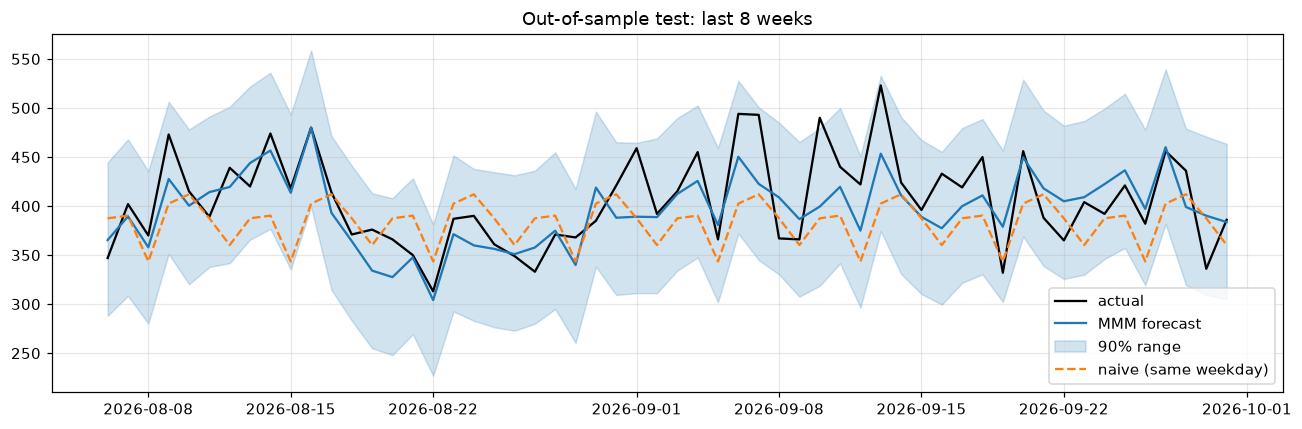

In [13]:
def metrics(actual, pred):
    err = pred - actual
    return {"MAE": np.mean(np.abs(err)),
            "MAPE %": np.mean(np.abs(err) / actual) * 100,
            "RMSE": np.sqrt(np.mean(err ** 2))}

def evaluate_holdout(data, test_start, test_end, label):
    train = data[data["date"] < test_start].reset_index(drop=True)
    test = data[(data["date"] >= test_start) & (data["date"] <= test_end)].reset_index(drop=True)
    print(f"{label}: train {len(train)} days (to {train['date'].max().date()}), test {len(test)} days")
    fit_tr = fit_model(train)
    diagnostics(fit_tr)

    draws = forecast(fit_tr, test)                         # (draws, days)
    actual = test["new_customers"].to_numpy()
    mean = draws.mean(axis=0)
    lo, hi = np.percentile(draws, [5, 95], axis=0)

    last28 = train.tail(28)
    flat = np.full(len(test), last28["new_customers"].mean())
    by_dow = last28.groupby(last28["date"].dt.dayofweek)["new_customers"].mean()
    seasonal_naive = test["date"].dt.dayofweek.map(by_dow).to_numpy()

    table = pd.DataFrame({
        "MMM (mean forecast)": metrics(actual, mean),
        "Naive: flat 28-day average": metrics(actual, flat),
        "Naive: same weekday, last 4 weeks": metrics(actual, seasonal_naive),
    }).T.round(1)
    coverage = float(np.mean((actual >= lo) & (actual <= hi)))

    weekly = pd.DataFrame({
        "week": (test["date"] - test["date"].min()).dt.days // 7 + 1,
        "MMM error %": np.abs(mean - actual) / actual * 100,
        "Naive (weekday) error %": np.abs(seasonal_naive - actual) / actual * 100,
    }).groupby("week").mean().round(1)

    display(table)
    print(f"Share of actual days inside the 90% prediction range: {coverage:.0%} (ideal is about 90%)")
    print("Average error by week (%):"); display(weekly)

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(test["date"], actual, color="black", label="actual")
    ax.plot(test["date"], mean, color="tab:blue", label="MMM forecast")
    ax.fill_between(test["date"], lo, hi, color="tab:blue", alpha=0.2, label="90% range")
    ax.plot(test["date"], seasonal_naive, color="tab:orange", ls="--", label="naive (same weekday)")
    ax.set_title(f"Out-of-sample test: {label}"); ax.legend()
    plt.tight_layout()
    plt.savefig(f"{OUT_DIR}/02_holdout_{label.replace(' ', '_')}.png"); plt.show()
    return {"fit": fit_tr, "table": table, "weekly": weekly, "coverage": coverage}

test_start = df["date"].max() - pd.Timedelta(days=HOLDOUT_DAYS - 1)
ho = evaluate_holdout(df, test_start, df["date"].max(), "last 8 weeks")

Max r_hat 1.005, min ESS 1,240, no divergences: the four chains agree and the sampler had no trouble. That says the fitting worked, not that the model is right. The tests below do that job.

What the hidden 8 weeks show
- The model beats both naive forecasts: MAE 25.7 vs 38.6-40.4 customers (MAPE 6.2% vs 9.1-9.5%), and it wins in every single week (4-9% error vs 7-14%).
- The model is given the real ad spend of those weeks and the naive forecasts are not, and the period is calm (no promotions). A useful test, not a hard one.
- No upward drift in the weekly error; the worst week is week 6 (9.4%).
- It follows the trend but misses some sharp highs and lows.
- 98% of days landed inside the 90% range, so the range is too wide rather than too tight. Probably, a single, constant noise level is estimated based on all 730 days, including periods of intense, high-volume sales.
- Good enough to compare spending plans for the next 30 days. Not proof that it works in sale periods.

## 5. Final model on all data

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [adstock_alpha, saturation_lam, saturation_beta, gamma_fourier, gamma_control, intercept_contribution, y_sigma]


Output()

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 275 seconds.


Output()

max r_hat  = 1.002   (want < 1.01)
min ESS    = 1476    (want > 400)
divergences= 0      (want 0 or very few)


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
adstock_alpha[bing],0.257,0.179,0.022,0.58,3461,1922,1.00,0.0026,0.0025
adstock_alpha[google],0.259,0.124,0.06,0.47,3293,1844,1.00,0.0021,0.0018
adstock_alpha[meta],0.648,0.045,0.57,0.72,3512,2936,1.00,0.00077,0.00072
adstock_alpha[pinterest],0.209,0.194,0.012,0.61,3498,2273,1.00,0.0032,0.0038
saturation_lam[bing],1.65,1.17,0.33,3.8,2188,1778,1.00,0.021,0.028
saturation_lam[google],6.95,1.87,4.2,10,1476,1523,1.00,0.048,0.029
saturation_lam[meta],1.15,0.51,0.43,2,1982,1898,1.00,0.011,0.0073
saturation_lam[pinterest],2,1.35,0.4,4.4,2324,2055,1.00,0.024,0.023
saturation_beta[bing],0.073,0.1,0.018,0.2,2029,1608,1.00,0.0027,0.0095
saturation_beta[google],0.0817,0.0119,0.067,0.1,1853,1535,1.00,0.00031,0.00045


Sampling: [y]


Output()

NOTE: predictions looked scaled, multiplying by the target scale.
In-sample MAPE: 8.0%   (this is NOT a test - the model has seen these days)


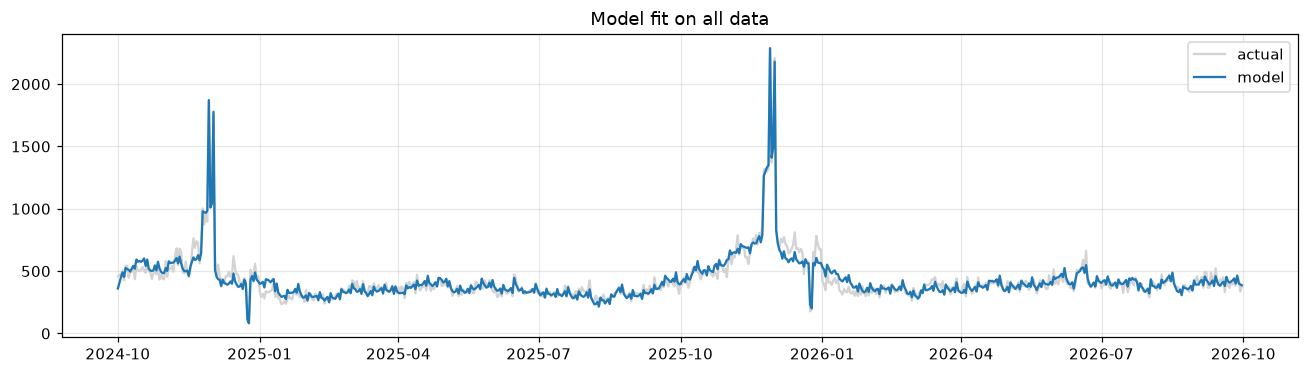

In [14]:
fit_full = fit_model(df)
diag = diagnostics(fit_full)
display(diag.loc[[i for i in diag.index if any(k in i for k in ("adstock", "saturation", "sigma"))]])

# in-sample fit
dr = forecast(fit_full, df, prepend=False)                   # predict the training period itself
m_in = dr.mean(axis=0)
y_all = df["new_customers"].to_numpy()
print("In-sample MAPE: {:.1f}%   (this is NOT a test - the model has seen these days)".format(
    np.mean(np.abs(m_in - y_all) / y_all) * 100))
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(df["date"], y_all, color="lightgrey", label="actual"); ax.plot(df["date"], m_in, color="tab:blue", label="model")
ax.set_title("Model fit on all data"); ax.legend(); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/03_insample_fit.png"); plt.show()

- Clean fit max r_hat = 1.002, min ESS = 1,476, no divergences.
- Meta's is the longest and best pinned down: alpha 0.65 (89% interval 0.57-0.72), with about 75% of its effect landing within three days. Bing, Google and Pinterest sit around 0.2-0.26 with wide intervals. Google's is clearly shorter than Meta's; for Bing and Pinterest the intervals overlap Meta's, so I can't rank them with confidence.
- Google's is the largest (6.95), so it saturates fastest. Meta's is small (1.15) with a wide interval (0.43-2): at today's spend its curve is nearly straight.
- Strength (beta) can't be compared between channels (each has its own scale and curve), so I compare marginal costs instead.
- Noise - y_sigma = 0.020 on the model's 0-1 scale, about 46 customers a day, roughly 12% of a typical day.
- The MAPE on the training set is 8% — the model has "seen" this data; furthermore, the spikes in sales are largely explained by the presence of discounts and "Black Friday" (BF) labels. This is not a test set.

## 6. The channel maths, re-implemented (used for scenarios and checks)
For each channel and day: spend / max spend -> adstock -> saturation -> x beta x target scale = customers. I coded this in NumPy and checked that it reproduces PyMC-Marketing's own channel contributions before using it.

In [15]:
def pick(post, prefix):
    names = [v for v in post.data_vars if v.startswith(prefix)]
    assert names, f"No variable starting with '{prefix}' in the posterior. Found: {list(post.data_vars)}"
    return post[names[0]]

def get_params(fit, n_keep=N_KEEP, seed=SEED):
    post = fit.mmm.idata.posterior
    out = {}
    for key, prefix in [("alpha", "adstock_alpha"), ("lam", "saturation_lam"), ("beta", "saturation_beta")]:
        da = pick(post, prefix)
        order = [str(c) for c in da.coords["channel"].values]
        arr = np.asarray(da.transpose("chain", "draw", "channel").values)
        arr = arr.reshape(-1, arr.shape[-1])[:, [order.index(c) for c in CHANNELS]]
        out[key] = arr
    total = out["alpha"].shape[0]
    sel = np.sort(np.random.default_rng(seed).choice(total, size=min(n_keep, total), replace=False))
    for k in ("alpha", "lam", "beta"):
        out[k] = out[k][sel]
    out.update(sel=sel, ch_scale=fit.ch_scale, tgt_scale=fit.tgt_scale, l_max=fit.l_max)
    return out

def adstock_np(x, alpha, l_max):
    """x: (days, channels) scaled spend; alpha: (draws, channels) -> (draws, days, channels)."""
    T, C = x.shape
    S = alpha.shape[0]
    w = alpha[:, None, :] ** np.arange(l_max)[None, :, None]      # weight of the spend j days ago
    w = w / w.sum(axis=1, keepdims=True)                          # weights add up to 1
    out = np.zeros((S, T, C))
    for j in range(l_max):
        if j == 0:
            out += w[:, j:j + 1, :] * x[None, :, :]
        else:
            out[:, j:, :] += w[:, j:j + 1, :] * x[None, :-j, :]
    return out

def saturation_np(a, lam):
    z = lam[:, None, :] * a
    return np.tanh(z / 2.0)                                       # = (1 - e^-z) / (1 + e^-z)

def contributions_np(spend, P):
    """spend: (days, channels) in £ -> customers contributed per draw/day/channel."""
    x = spend / P["ch_scale"]
    a = adstock_np(x, P["alpha"], P["l_max"])
    s = saturation_np(a, P["lam"])
    return P["beta"][:, None, :] * s * P["tgt_scale"]

def library_contributions(fit, P):
    mmm = fit.mmm
    try:
        da = mmm.compute_channel_contribution_original_scale()
        scale = 1.0
        src = "compute_channel_contribution_original_scale()"
    except Exception:
        da = pick(mmm.idata.posterior, "channel_contribution")
        scale = fit.tgt_scale
        src = "posterior['channel_contribution'] x target scale"
    order = [str(c) for c in da.coords["channel"].values]
    arr = np.asarray(da.transpose("chain", "draw", "date", "channel").values) * scale
    arr = arr.reshape(-1, arr.shape[-2], arr.shape[-1])[:, :, [order.index(c) for c in CHANNELS]]
    return arr[P["sel"]], src

def validate_engine(fit, P, tol=0.01):
    lib, src = library_contributions(fit, P)
    mine = contributions_np(fit.data[CHANNELS].to_numpy(), P)
    rel = np.abs(mine - lib).max() / lib.mean()
    print(f"Library numbers taken from: {src}")
    print(f"Largest difference between my NumPy maths and the library: {rel:.4%} of the average contribution")
    if rel < tol:
        print("PASS: my re-implementation reproduces the library.")
    else:
        print("MISMATCH: do NOT use the scenario numbers yet. The scaling/adstock/saturation differs from my assumption.")
    return rel

P = get_params(fit_full)
validate_engine(fit_full, P)

# helpers used everywhere below
def total_customers(P, vec):
    """Customers from the 4 channels over the horizon if every day we spend `vec` (£ per channel)."""
    plan = np.tile(vec, (HORIZON, 1))
    c = contributions_np(np.vstack([hist, plan]), P)[:, -HORIZON:, :]
    return c.sum(axis=(1, 2))                                     # one number per posterior draw

def delta_customers(P, vec, base_vec=None):
    base_vec = base_daily.to_numpy() if base_vec is None else base_vec
    return total_customers(P, vec) - total_customers(P, base_vec)

# what does the model attribute to each channel over the 2 years?
tot = contributions_np(df[CHANNELS].to_numpy(), P).sum(axis=1).mean(axis=0)
attr = pd.DataFrame({"spend £": df[CHANNELS].sum().round(0), "customers attributed": tot.round(0)})
attr["avg £ per attributed customer"] = (attr["spend £"] / attr["customers attributed"]).round(1)
attr["share of all new customers"] = (attr["customers attributed"] / df["new_customers"].sum()).round(3)
display(attr)

Library numbers taken from: posterior['channel_contribution'] x target scale
Largest difference between my NumPy maths and the library: 0.0000% of the average contribution
PASS: my re-implementation reproduces the library.


,spend £,customers attributed,avg £ per attributed customer,share of all new customers
bing,242284.0,16983.0,14.3,0.054
google,1676880.0,67234.0,24.9,0.215
meta,2099197.0,77372.0,27.1,0.247
pinterest,364680.0,11537.0,31.6,0.037


- My NumPy version matches the library (0.0000% gap), so I can use it for scenarios.
- The model credits advertising with about 55% of all new customers; the rest is baseline, season and promotions.
- Average cost per attributed customer: Bing £14, Google £25, Meta £27, Pinterest £32. All below £40, but these are *averages*, not what the next customer costs.
- Meta brings the most customers (24.7%), Google is close behind (21.5%), then Bing (5.4%) and Pinterest (3.7%).

## 7. Worked example: one channel (Meta), step by step

Posterior means for meta: alpha (carry-over) = 0.647, lambda (saturation speed) = 1.154, beta (strength) = 0.683
Max daily meta spend in the data (the 'scale') = £19,251; target scale = 2290 customers

Adstock weights (share of today's effect that comes from spend 0, 1, 2, ... days ago):
0 d ago    0.365
1 d ago    0.236
2 d ago    0.152
3 d ago    0.099
4 d ago    0.064
5 d ago    0.041
6 d ago    0.027
7 d ago    0.017


,date,1. spend £,2. spend / max,3. after adstock,4. after saturation,5. x beta x scale = customers
0,2026-09-23,2094.0,0.109,0.102,0.059,92.3
1,2026-09-24,2063.0,0.107,0.104,0.060,93.9
2,2026-09-25,2113.0,0.110,0.106,0.061,95.5
3,2026-09-26,2002.0,0.104,0.105,0.061,94.8
4,2026-09-27,1809.0,0.094,0.101,0.058,91.1
5,2026-09-28,2649.0,0.138,0.114,0.066,103.1
6,2026-09-29,2779.0,0.144,0.125,0.072,113.0
7,2026-09-30,2351.0,0.122,0.125,0.072,112.3



meta +20% for 30 days: extra spend £15,056
  extra customers (average over all draws): 526  (90% range 488 to 566)
  extra customers from the average parameters: 664  (higher: the parameters are correlated, so averaging them first gives an unrealistic mix)
  cost per extra customer = £15,056 / 526 = £28.6  -> below the £40 target


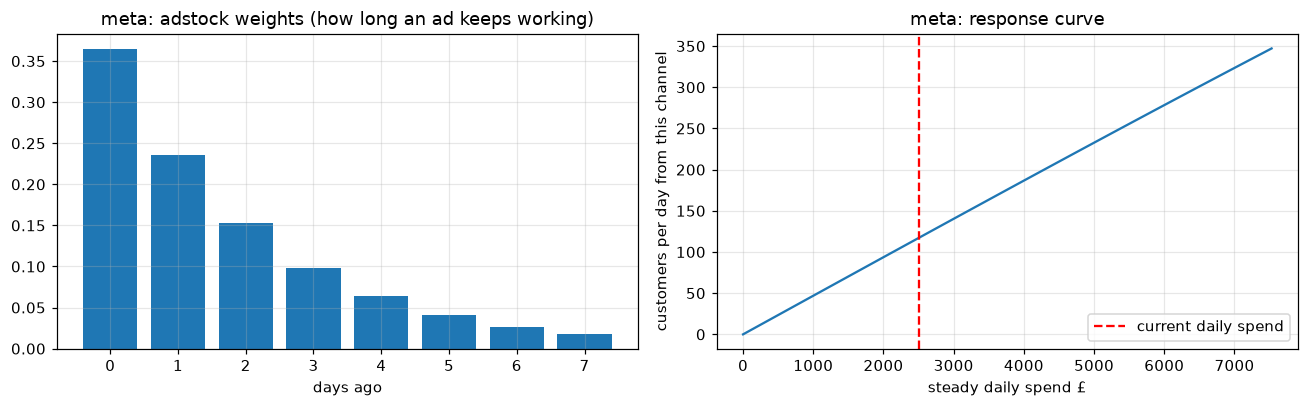

In [16]:
EX = "meta"
c = CHANNELS.index(EX)
P_mean = {k: P[k].mean(axis=0, keepdims=True) for k in ("alpha", "lam", "beta")}
P_mean.update(ch_scale=P["ch_scale"], tgt_scale=P["tgt_scale"], l_max=P["l_max"])
a, lam, beta = P_mean["alpha"][0, c], P_mean["lam"][0, c], P_mean["beta"][0, c]
L = P["l_max"]

print(f"Posterior means for {EX}: alpha (carry-over) = {a:.3f}, lambda (saturation speed) = {lam:.3f}, beta (strength) = {beta:.3f}")
print(f"Max daily {EX} spend in the data (the 'scale') = £{P['ch_scale'][c]:,.0f}; target scale = {P['tgt_scale']:.0f} customers")

weights = a ** np.arange(L); weights = weights / weights.sum()
print("\nAdstock weights (share of today's effect that comes from spend 0, 1, 2, ... days ago):")
print(pd.Series(weights.round(3), index=[f"{j} d ago" for j in range(L)]).to_string())

# step by step for the last 8 days of the data
spend_all = df[CHANNELS].to_numpy()
x = spend_all / P["ch_scale"]
ad = adstock_np(x, P_mean["alpha"], L)[0]
sat = saturation_np(ad[None], P_mean["lam"])[0]
cust = P_mean["beta"][0] * sat * P["tgt_scale"]
steps = pd.DataFrame({
    "date": df["date"].tail(8).dt.date.to_numpy(),
    "1. spend £": spend_all[-8:, c].round(0),
    "2. spend / max": x[-8:, c].round(3),
    "3. after adstock": ad[-8:, c].round(3),
    "4. after saturation": sat[-8:, c].round(3),
    "5. x beta x scale = customers": cust[-8:, c].round(1),
})
display(steps)

# the business question for this channel: +20% for 30 days
vec = base_daily.to_numpy().copy(); vec[c] *= 1.20
d_all = delta_customers(P, vec)                    # all posterior draws
d_mean_params = delta_customers(P_mean, vec)[0]    # using only the average parameters
extra_spend = base_daily[EX] * 0.20 * HORIZON
print(f"\n{EX} +20% for {HORIZON} days: extra spend £{extra_spend:,.0f}")
print(f"  extra customers (average over all draws): {d_all.mean():,.0f}  (90% range {np.percentile(d_all, 5):,.0f} to {np.percentile(d_all, 95):,.0f})")
print(f"  extra customers from the average parameters: {d_mean_params:,.0f}  (higher: the parameters are correlated, so averaging them first gives an unrealistic mix)")
print(f"  cost per extra customer = £{extra_spend:,.0f} / {d_all.mean():,.0f} = £{extra_spend / d_all.mean():,.1f}  -> {'below' if extra_spend / d_all.mean() <= CPA_TARGET else 'ABOVE'} the £{CPA_TARGET:.0f} target")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].bar(range(L), weights); axes[0].set_xlabel("days ago"); axes[0].set_title(f"{EX}: adstock weights (how long an ad keeps working)")
grid = np.linspace(0, 3 * base_daily[EX], 100)
curve = beta * np.tanh(lam * (grid / P["ch_scale"][c]) / 2) * P["tgt_scale"]
axes[1].plot(grid, curve); axes[1].axvline(base_daily[EX], color="red", ls="--", label="current daily spend")
axes[1].set_xlabel("steady daily spend £"); axes[1].set_ylabel("customers per day from this channel")
axes[1].set_title(f"{EX}: response curve"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/04_worked_example_{EX}.png"); plt.show()

- Meta's carry-over is 0.65. Today's spend gives 36.5% of the effect, yesterday's 23.6%, the day before 15.2%. It is mostly gone within a week.
- Why the curve is straight: today's Meta spend (about £2.5k a day) is only 13% of its Black Friday peak (£19k), so we sit on the early, almost straight part of the curve. Extra money still pays at nearly the same rate.
- +£15k over 30 days brings about 526 extra customers (90% range 488-566), roughly £28.6 each, under the £40 limit.
- A trap I avoided: if you were to average the parameters first, you would arrive at a more optimistic figure—664 clients. Meta’s parameters are interconnected, and averaging them destroys that connection. The headline, by contrast, uses the full range of the sample (526).
- This is a model estimate, not a promise. It is based on the low level of saturation that the model detects on the Meta platform.

## 8. Independent checks

In [17]:
# --- inputs for the checks ---
EX = "meta"
c = CHANNELS.index(EX)
L = P["l_max"]
base_vec = base_daily.to_numpy()
vec = base_vec.copy()
vec[c] *= 1.20                       # the change we test: Meta +20% for 30 days

# (a) same plan against itself must give exactly zero change
d_self = delta_customers(P, base_vec, base_vec)
print(f"(a) Baseline vs itself: max |change| = {np.abs(d_self).max():.12f} customers ->",
      "PASS" if np.abs(d_self).max() < 1e-9 else "FAIL")

# (b) manual recalculation of one change, written with plain Python loops (no vectorised code)
def manual_customers(daily_spend_list, a, lam, beta, ch_scale, tgt_scale, l_max):
    w = [a ** k for k in range(l_max)]
    tot_w = sum(w)
    w = [v / tot_w for v in w]
    out = []
    for t in range(len(daily_spend_list)):
        ad = sum(w[k] * daily_spend_list[t - k] / ch_scale for k in range(l_max) if t - k >= 0)
        sat = (1 - math.exp(-lam * ad)) / (1 + math.exp(-lam * ad))
        out.append(beta * sat * tgt_scale)
    return out

s = 0                                                     # one real posterior draw (not the average parameters)
a_s, lam_s, beta_s = P["alpha"][s, c], P["lam"][s, c], P["beta"][s, c]

hist_c = list(hist[:, c])
base_list = [float(base_daily[EX])] * HORIZON
plus_list = [float(base_daily[EX]) * 1.20] * HORIZON
cb = manual_customers(hist_c + base_list, a_s, lam_s, beta_s, P["ch_scale"][c], P["tgt_scale"], L)[-HORIZON:]
cp = manual_customers(hist_c + plus_list, a_s, lam_s, beta_s, P["ch_scale"][c], P["tgt_scale"], L)[-HORIZON:]
manual_delta = sum(cp) - sum(cb)
manual_spend = sum(plus_list) - sum(base_list)
engine_delta = delta_customers(P, vec)[s]                 # the same draw in the vectorised engine

print(f"(b) Posterior draw #{s}, {EX} +20%: manual loops give {manual_delta:,.3f} extra customers "
      f"for £{manual_spend:,.0f} -> £{manual_spend / manual_delta:,.2f} each")
print(f"    vectorised engine gives {engine_delta:,.3f} ->",
      "PASS" if abs(manual_delta - engine_delta) < 1e-6 else "FAIL")
d_all = delta_customers(P, vec)
print(f"    Headline figure (average over ALL draws): {d_all.mean():,.0f} extra customers "
      f"-> £{manual_spend / d_all.mean():,.2f} each")

# (c) change one input and see whether the answer makes sense: bigger and bigger Meta increases
rows = []
for pct in [0.10, 0.20, 0.40, 0.80]:
    v = base_vec.copy(); v[c] *= 1 + pct
    dd = delta_customers(P, v)
    sp = base_daily[EX] * pct * HORIZON
    rows.append({"Meta increase": f"+{pct:.0%}", "extra spend £": round(sp), "extra customers": round(dd.mean()),
                 "cost per extra customer £": round(sp / dd.mean(), 2)})
chk = pd.DataFrame(rows); display(chk)
rise = chk["cost per extra customer £"].iloc[-1] / chk["cost per extra customer £"].iloc[0] - 1
print(f"(c) cost per extra customer changes by {rise:.1%} between +10% and +80%:",
      "clear diminishing returns" if rise > 0.05 else "almost flat -> little diminishing returns visible for this channel in this range")

# (d) switching a channel off: customers lost should be positive and comparable to what the model attributes to it
v0 = base_vec.copy()
v0[c] = 0.0
lost = -delta_customers(P, v0)
print(f"(d) Switching {EX} off for {HORIZON} days loses about {lost.mean():,.0f} customers "
      f"(90% range {np.percentile(lost, 5):,.0f}-{np.percentile(lost, 95):,.0f}); "
      f"saving £{base_daily[EX] * HORIZON:,.0f} -> £{base_daily[EX] * HORIZON / lost.mean():,.1f} per customer lost")

(a) Baseline vs itself: max |change| = 0.000000000000 customers -> PASS
(b) Posterior draw #0, meta +20%: manual loops give 501.875 extra customers for £15,056 -> £30.00 each
    vectorised engine gives 501.875 -> PASS
    Headline figure (average over ALL draws): 526 extra customers -> £28.63 each


,Meta increase,extra spend £,extra customers,cost per extra customer £
0,+10%,7528,263,28.61
1,+20%,15056,526,28.63
2,+40%,30113,1050,28.67
3,+80%,60226,2093,28.77


(c) cost per extra customer changes by 0.6% between +10% and +80%: almost flat -> little diminishing returns visible for this channel in this range
(d) Switching meta off for 30 days loses about 2,645 customers (90% range 2,446-2,847); saving £75,282 -> £28.5 per customer lost


In [18]:
# Stress test: what does the NEXT £ cost at much larger spend? (far beyond normal, illustration only)
base_vec = base_daily.to_numpy()
mults_long = [1.1, 2.5, 5.0, 7.5]
rows = []
for i, ch in enumerate(CHANNELS):
    prev_m, prev_d = 1.0, 0.0
    for m in mults_long:
        v = base_vec.copy(); v[i] *= m
        d = delta_customers(P, v).mean()
        step_spend = base_daily[ch] * (m - prev_m) * HORIZON
        rows.append({"channel": ch, "spend vs now": f"{m}x",
                     "cost of this step £": round(step_spend / (d - prev_d), 1)})
        prev_m, prev_d = m, d
table = pd.DataFrame(rows).pivot(index="channel", columns="spend vs now", values="cost of this step £")
display(table.reindex(CHANNELS)[[f"{m}x" for m in mults_long]])
print("Note: 5x and 7.5x are far above normal spend (Meta 7.5x is about £18.8k/day, close to its Black Friday peak). Illustration, not a forecast.")

spend vs now,1.1x,2.5x,5.0x,7.5x
channel,,,,
bing,15.4,17.9,27.1,43.8
google,31.6,53.6,249.7,1912.1
meta,28.6,29.0,31.0,35.4
pinterest,33.3,36.9,51.0,78.0


Note: 5x and 7.5x are far above normal spend (Meta 7.5x is about £18.8k/day, close to its Black Friday peak). Illustration, not a forecast.


- Baseline vs itself gives exactly 0, and a hand-written loop (on one posterior draw) matches the vectorised engine to six decimals.
- Meta's cost barely moves from +10% to +80% (£28.61 to £28.77, +0.6%). That is not a bug: the same code makes Google bend sharply. Meta simply sits on the straight start of its curve.
- Far beyond today's spend (5-7.5x, the Black Friday zone) the step cost climbs for every channel: Google's explodes, Meta's climbs much more slowly. Pure extrapolation, so illustration only.
- Switching Meta off for 30 days loses about 2,645 customers (range 2,446-2,847) and saves £75k, or £28.5 per customer lost. Meta clearly matters.

## 9. Five spending plans (30 days)
Proportional plans (+10%, +20%, -10%) scale every channel by the same percentage, so the mix stays the same. The reallocation plan moves money from the channel with the highest marginal cost to the one with the lowest (marginal cost = extra £ / extra customers for a +10% step in that channel alone). At most 20% of the donor's budget moves, and the receiver may grow to at most 1.5x its current spend, to stay close to levels the data has actually seen.

,extra spend £ (30d),extra customers (mean),marginal cost £ per extra customer,P(cost < £40)
bing,994.33,64.39,15.44,0.99
google,6794.86,214.87,31.62,0.99
meta,7528.20,263.17,28.61,1.00
pinterest,1903.54,57.24,33.25,0.71


Cheapest extra customers: bing   |   most expensive: pinterest
Reallocation: move £127 per day (£3,807 over 30 days) from pinterest to bing


Scenario,1. Keep spend (baseline),2. +10% all channels,3. +20% all channels,4. -10% all channels,"5. Move £3,807 from pinterest to bing"
bing £,9943.25,10937.58,11931.90,8948.93,13750.33
google £,67948.60,74743.46,81538.32,61153.74,67948.60
meta £,75282.03,82810.23,90338.44,67753.83,75282.03
pinterest £,19035.42,20938.96,22842.50,17131.88,15228.34
Total spend £,172209.30,189430.23,206651.16,154988.37,172209.30
Change in spend £,0.00,17220.93,34441.86,-17220.93,-0.00
New customers (expected),12558.00,13157.67,13741.06,11942.02,12681.78
Change in customers (mean),0.00,599.67,1183.06,-615.98,123.78
Change 5%,0.00,557.47,1098.48,-662.55,0.45
Change 95%,0.00,641.31,1261.60,-568.36,244.89


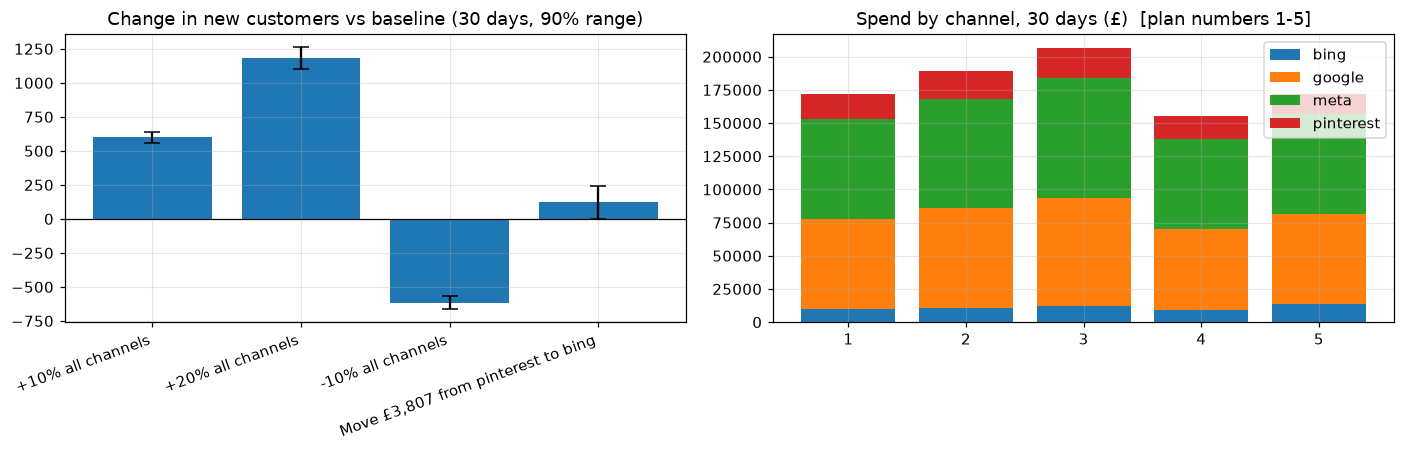

In [19]:
def channel_marginal_cpa(P, step=0.10):
    base = base_daily.to_numpy()
    out = {}
    for i, ch in enumerate(CHANNELS):
        v = base.copy(); v[i] *= 1 + step
        d = delta_customers(P, v, base)
        dspend = base[i] * step * HORIZON
        with np.errstate(divide="ignore", invalid="ignore"):
            p_ok = np.mean((d > 0) & (dspend / np.where(d > 0, d, np.nan) <= CPA_TARGET))
        out[ch] = {"extra spend £ (30d)": dspend, "extra customers (mean)": d.mean(),
                   "marginal cost £ per extra customer": dspend / d.mean(), "P(cost < £40)": p_ok}
    return pd.DataFrame(out).T

marg = channel_marginal_cpa(P)
display(marg.round(2))
best_ch = marg["marginal cost £ per extra customer"].astype(float).idxmin()
worst_ch = marg["marginal cost £ per extra customer"].astype(float).idxmax()
MOVE_SHARE = 0.20            # at most this share of the most expensive channel's budget is moved
MAX_RECEIVER_MULT = 1.5      # the receiving channel may grow at most to 1.5x its current spend

base = base_daily.to_numpy()
iw, ib = CHANNELS.index(worst_ch), CHANNELS.index(best_ch)
moved = min(base[iw] * MOVE_SHARE, base[ib] * (MAX_RECEIVER_MULT - 1))     # £ per day
realloc = base.copy()
realloc[iw] -= moved
realloc[ib] += moved
assert abs(realloc.sum() - base.sum()) < 1e-6, "reallocation must keep the total budget unchanged"
print(f"Cheapest extra customers: {best_ch}   |   most expensive: {worst_ch}")
print(f"Reallocation: move £{moved:,.0f} per day (£{moved * HORIZON:,.0f} over {HORIZON} days) from {worst_ch} to {best_ch}")

SCEN = {
    "1. Keep spend (baseline)": base,
    "2. +10% all channels": base * 1.10,
    "3. +20% all channels": base * 1.20,
    "4. -10% all channels": base * 0.90,
    f"5. Move £{moved * HORIZON:,.0f} from {worst_ch} to {best_ch}": realloc,
}
BASE_KEY = "1. Keep spend (baseline)"

def evaluate(P, scen, base_key):
    base_vec = scen[base_key]
    base_spend = base_vec.sum() * HORIZON
    rows, draws = [], {}
    for name, vec in scen.items():
        d = delta_customers(P, vec, base_vec)
        dspend = vec.sum() * HORIZON - base_spend
        draws[name] = d
        row = {"Scenario": name}
        for ch, v in zip(CHANNELS, vec):
            row[f"{ch} £"] = v * HORIZON
        row["Total spend £"] = vec.sum() * HORIZON
        row["Change in spend £"] = dspend
        row["New customers (expected)"] = base_new_30d + d.mean()
        row["Change in customers (mean)"] = d.mean()
        row["Change 5%"], row["Change 95%"] = np.percentile(d, [5, 95])
        with np.errstate(divide="ignore", invalid="ignore"):
            if dspend > 1e-9:
                row["Cost per extra customer £"] = dspend / d.mean() if d.mean() > 0 else np.nan
                row["P(cost < £40)"] = np.mean((d > 0) & (dspend / d <= CPA_TARGET))
            elif dspend < -1e-9:
                row["Money saved £"] = -dspend
                row["Customers lost"] = -d.mean()
                row["Saved per customer lost £"] = (-dspend) / (-d.mean()) if d.mean() < 0 else np.nan
                row["P(saved per lost customer > £40)"] = np.mean((d < 0) & ((-dspend) / (-d) > CPA_TARGET))
            elif name != base_key:
                row["P(more customers than baseline)"] = np.mean(d > 0)
        rows.append(row)
    return pd.DataFrame(rows).set_index("Scenario"), draws

scen_table, scen_draws = evaluate(P, SCEN, BASE_KEY)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
display(scen_table.round(2).T)
scen_table.round(2).to_csv(f"{OUT_DIR}/scenario_table.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
names = list(SCEN.keys())[1:]
means = [scen_draws[n].mean() for n in names]
err_lo = [scen_draws[n].mean() - np.percentile(scen_draws[n], 5) for n in names]
err_hi = [np.percentile(scen_draws[n], 95) - scen_draws[n].mean() for n in names]
axes[0].bar(range(len(names)), means, yerr=[err_lo, err_hi], capsize=5, color="tab:blue")
axes[0].set_xticks(range(len(names))); axes[0].set_xticklabels([n.split(". ")[1] for n in names], rotation=20, ha="right")
axes[0].axhline(0, color="black", lw=0.8); axes[0].set_title("Change in new customers vs baseline (30 days, 90% range)")
bottom = np.zeros(len(SCEN))
for i, ch in enumerate(CHANNELS):
    vals = np.array([v[i] * HORIZON for v in SCEN.values()])
    axes[1].bar(range(len(SCEN)), vals, bottom=bottom, label=ch); bottom += vals
axes[1].set_xticks(range(len(SCEN))); axes[1].set_xticklabels([n.split(". ")[0] for n in SCEN])
axes[1].set_title("Spend by channel, 30 days (£)  [plan numbers 1-5]"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/05_scenarios.png"); plt.show()

- One channel at a time (+10%). Every channel costs less than £40 per extra customer: Bing £15, Meta £29, Google £32, Pinterest £33. Pinterest is the shakiest (only 71% of model draws stay under £40).
- Plans 2 and 3: +10% across the board adds about 600 customers (range 557-641) at £28.7 each; +20% adds about 1,183 (1,098-1,262) at £29.1 each.
- Plan 4: -10% saves £17.2k and loses about 616 customers, so £28 saved per customer lost. That is under £40, so cutting is not attractive.
- Plan 5: moving £3.8k from Pinterest to Bing gains only about 124 customers (+1%; range 0-245). The model calls it 95% likely to beat the baseline, but the win is small.
- Bing is the cheapest but tiny: +10% adds only about 64 customers. Its reallocation is capped at 1.5x because the data has not seen much more.

## 10. How far can each channel go? Response curves and the £40 ceiling

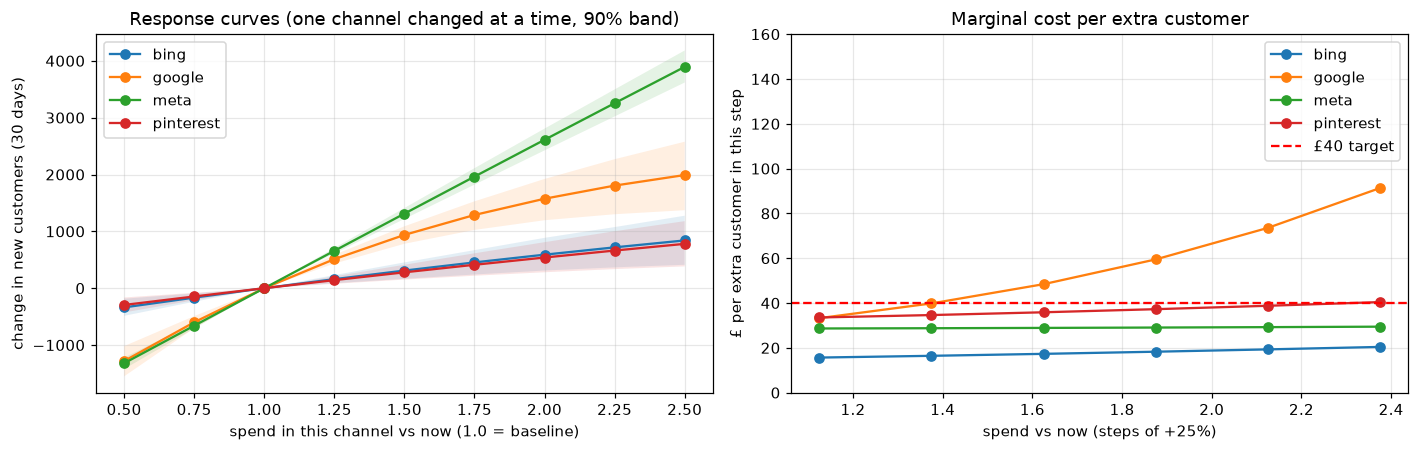

,daily spend £,marginal cost £ (+10% step),P(cost < £40),share of max effect already reached,spend ceiling for £40
bing,331.0,15.4,0.99,0.22,above 2.50x (not reached)
google,2265.0,31.6,0.99,0.52,about 1.50x current spend
meta,2509.0,28.6,1.00,0.07,above 2.50x (not reached)
pinterest,635.0,33.3,0.71,0.18,about 2.25x current spend


In [20]:
mults = np.round(np.arange(0.5, 2.51, 0.25), 2)
curves = {}
for i, ch in enumerate(CHANNELS):
    rows = []
    for m in mults:
        v = base.copy(); v[i] *= m
        d = delta_customers(P, v, base)
        rows.append({"mult": m, "extra_spend": base[i] * (m - 1) * HORIZON,
                     "d_mean": d.mean(), "d_lo": np.percentile(d, 5), "d_hi": np.percentile(d, 95)})
    curves[ch] = pd.DataFrame(rows)

def ceiling(cdf):
    up = cdf[cdf["mult"] >= 1.0].reset_index(drop=True)
    for k in range(1, len(up)):
        step_spend = up.loc[k, "extra_spend"] - up.loc[k - 1, "extra_spend"]
        step_cust = up.loc[k, "d_mean"] - up.loc[k - 1, "d_mean"]
        if step_cust <= 0 or step_spend / step_cust > CPA_TARGET:
            return "already above £40 at the margin" if k == 1 else f"about {up.loc[k - 1, 'mult']:.2f}x current spend"
    return f"above {up['mult'].max():.2f}x (not reached)"

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ch in CHANNELS:
    cdf = curves[ch]
    axes[0].plot(cdf["mult"], cdf["d_mean"], marker="o", label=ch)
    axes[0].fill_between(cdf["mult"], cdf["d_lo"], cdf["d_hi"], alpha=0.12)
    up = cdf[cdf["mult"] >= 1.0].reset_index(drop=True)
    step_spend = up["extra_spend"].diff(); step_cust = up["d_mean"].diff()
    axes[1].plot((up["mult"] - 0.125)[1:], (step_spend / step_cust)[1:], marker="o", label=ch)
axes[0].set_xlabel("spend in this channel vs now (1.0 = baseline)"); axes[0].set_ylabel("change in new customers (30 days)")
axes[0].set_title("Response curves (one channel changed at a time, 90% band)"); axes[0].legend()
axes[1].axhline(CPA_TARGET, color="red", ls="--", label=f"£{CPA_TARGET:.0f} target")
axes[1].set_xlabel("spend vs now (steps of +25%)"); axes[1].set_ylabel("£ per extra customer in this step")
axes[1].set_title("Marginal cost per extra customer"); axes[1].set_ylim(0, 4 * CPA_TARGET); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/06_response_curves.png"); plt.show()

sat_share = np.median(np.tanh(P["lam"] * (base / P["ch_scale"]) / 2), axis=0)
channel_table = pd.DataFrame({
    "daily spend £": base_daily.round(0),
    "marginal cost £ (+10% step)": marg["marginal cost £ per extra customer"].astype(float).round(1),
    "P(cost < £40)": marg["P(cost < £40)"].astype(float).round(2),
    "share of max effect already reached": pd.Series(sat_share, index=CHANNELS).round(2),
    "spend ceiling for £40": pd.Series({ch: ceiling(curves[ch]) for ch in CHANNELS}),
})
display(channel_table)
channel_table.to_csv(f"{OUT_DIR}/channel_table.csv")

- Meta: the line is nearly straight and the cost of the next step stays near £29 all the way to 2.5x, with the narrowest band of the four. It looks like the best place to scale, but this assumes that the model experiences virtually no saturation.
- Google: bends first. It has already used 52% of its maximum effect, and extra money passes £40 at roughly 1.5x today's spend (about £3.4k a day).
- Bing: cheapest (£15) and still under £40 beyond 2.5x, but small in absolute terms.
- Pinterest: reaches £40 at about 2.25x today's spend. Small, and the least certain (71% under £40).

## 11. Recommendation and a small practical test

Recommendation
- Add to Meta first. Biggest lever (+10% is about +263 customers) at about £29 each. Test before scaling big.
- Add some to Bing. Cheapest (£15), but +10% is only about 64 customers.
- Google: a moderate increase only, well short of 1.5x today's spend.
- Pinterest: hold. Highest marginal cost and the least certain.
- Do not cut anything for the sake of cost savings. If the total budget must remain unchanged, fund any increased spending by reallocating from Pinterest and Google—while anticipating only a modest gain.

In [21]:
# --- choose the test ----------------------------------------------------------
test_channel = "meta"      # channel to test (the biggest volume lever)
test_pct = 0.20            # size of the increase: +20% for 30 days

cheapest = channel_table["marginal cost £ (+10% step)"].astype(float).idxmin()        # for information only
most_expensive = channel_table["marginal cost £ (+10% step)"].astype(float).idxmax()  # for information only

v = base_daily.to_numpy().copy()
v[CHANNELS.index(test_channel)] *= 1 + test_pct
d = delta_customers(P, v)
extra = base_daily[test_channel] * test_pct * HORIZON
lo, hi = np.percentile(d, [5, 95])

print(f"TEST: raise {test_channel} by {test_pct:.0%} for {HORIZON} days")
print(f"  budget: from £{base_daily[test_channel] * HORIZON:,.0f} to £{base_daily[test_channel] * HORIZON + extra:,.0f} (extra £{extra:,.0f})")
print(f"  model expects {d.mean():,.0f} extra customers (90% range {lo:,.0f} to {hi:,.0f}), about £{extra / d.mean():,.1f} per extra customer")
print(f"  per week: about {d.mean() * 7 / HORIZON:,.0f} extra customers (range {lo * 7 / HORIZON:,.0f} to {hi * 7 / HORIZON:,.0f})")
print("  decision rules, reviewed weekly:")
print(f"    INCREASE further if the measured cost per extra customer <= £{CPA_TARGET:.0f} and results are inside the predicted range")
print(f"    REDUCE / stop if the measured cost per extra customer > £{CPA_TARGET:.0f} for two weeks in a row")
print("    INVESTIGATE if results fall outside the 90% range (promotion, stock, tracking change, competitor, seasonality)")
print(f"  for information: cheapest extra customers: {cheapest}; highest marginal cost: {most_expensive}")
display(channel_table)

TEST: raise meta by 20% for 30 days
  budget: from £75,282 to £90,338 (extra £15,056)
  model expects 526 extra customers (90% range 488 to 566), about £28.6 per extra customer
  per week: about 123 extra customers (range 114 to 132)
  decision rules, reviewed weekly:
    INCREASE further if the measured cost per extra customer <= £40 and results are inside the predicted range
    REDUCE / stop if the measured cost per extra customer > £40 for two weeks in a row
    INVESTIGATE if results fall outside the 90% range (promotion, stock, tracking change, competitor, seasonality)
  for information: cheapest extra customers: bing; highest marginal cost: pinterest


,daily spend £,marginal cost £ (+10% step),P(cost < £40),share of max effect already reached,spend ceiling for £40
bing,331.0,15.4,0.99,0.22,above 2.50x (not reached)
google,2265.0,31.6,0.99,0.52,about 1.50x current spend
meta,2509.0,28.6,1.00,0.07,above 2.50x (not reached)
pinterest,635.0,33.3,0.71,0.18,about 2.25x current spend


The test: Meta +20% for 30 days
- Budget: £75k to £90k (+£15k).
- Model estimate (to be confirmed by the test, not a guarantee): about +530 customers (90% range 490-570), roughly £29 each against the £40 limit. That is about 120 a week.
- Weekly review: scale up if the measured cost per extra customer is £40 or less and results sit inside the predicted range; stop if it is above £40 two weeks in a row; investigate if results fall outside the range (promotion, stock-out, tracking change, competitor, season).
- Keep a control group (for example a few regions stay on the old budget). That separates ads from season and promotions. Without one, the “measured” value relies on the model’s own forecast.
- Why +20% and not +10%? +10% (about 260 customers over the month) is easy to lose in daily noise. +20% is big enough to see and still close to spend levels the model knows.

## 12. Limits, and how AI was used

**Trust more**
- All four channels are under £40 per extra customer at today's spend; Bing is the cheapest and Google gets expensive first.
- The maths is checked: my NumPy version matches the library (0.0000% gap), a manual loop matches it, and baseline vs itself gives 0.
- I did not refit with other assumptions (ad memory length, seasonality), so I can't say these conclusions survive them.

**Needs more evidence**
- Meta not saturating. Saturation is hard to see when spend is far below its peak, and the high-spend days are Black Friday days with big discounts. A rough cross-check from the data: the 2025 sale had £158k more spend than 2024 (same discounts) and 3,559 more customers, about £44 each. This is not a direct comparison, but the figure exceeds the £29 incorporated into the model; therefore, actual costs during the sales phase could rise more rapidly.
- Pinterest (wide range), any investments exceeding current spending by more than 20–40%, as well as the effects of promotional campaigns (the available data includes only two instances of "Black Friday").
- The ranges only reflect uncertainty in the fitted parameters, not the chance that the model's structure is wrong. The 98% coverage shows they are too wide.
- The 30-day window ignores effects after day 30, so extra customers are slightly understated.

**I would reject the results if** 
- r_hat > 1.01 or there were divergences
- the NumPy check disagreed with the library
- the model lost to a plain weekday average
- the conclusions flipped under small changes to the assumptions.

**Prediction is not causation.** 
- Spend rises with discounts and season, ad platforms show ads to people who would have bought anyway, and there are only 730 days. Only a controlled test, like the Meta +20% above, shows what ads really cause.

---

**How AI was used.** AI wrote the first version of the code and the draft text. I ran it, checked it and corrected it. What got caught:
- Units: the first version only printed the units. I added real checks (ranges, whole numbers, revenue-to-spend ratio, order value).
- Unusual days: it used made-up cut-offs (0.5x and 1.6x of the median). I replaced them with a rolling median/MAD rule, and added a spend column because it only looked at customers.
- Model target: the library needs the target to be called y; the first version crashed.
- Variable name: the library calls it 'channel_contribution', not 'channel_contributions'; the engine check failed until fixed.
- Meta's flat curve: it was initially noted that this is “logical (the law of diminishing returns),” even though costs increased by only 0.6%. Now, the exact figure for this increase is provided, and I have offered an explanation for it (the initial segment of the curve is linear; in Google’s case, using the same code, the curve bends).
- Averaged parameters: in the example provided, 664 clients were identified based on averaged parameters, with the discrepancy characterized as insignificant. When all samples are taken into account, however, the result is 526; thus, the manual check relies on one specific sample, whereas the figure in the heading incorporates all of them.
- Test channel: the draft picked the cheapest channel (Bing) instead of the one I meant (Meta). The channel is now set explicitly.
- Over-confident wording in my first notes ("configured just right", "guaranteed", "mathematical proof", Google "can absorb bigger budgets" when its high lambda means it saturates fastest) was rewritten after checking against the numbers.